In [3]:
import pickle, random, time
from pathlib import Path

import igraph as ig
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent
PROCESSED = REPO_ROOT / "data" / "processed"
NULLS     = PROCESSED / "nulls"
RESULTS   = REPO_ROOT / "results"
FIGURES   = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42          # Louvain seed, same as louvain.ipynb
N_RANDOM = 20      # random-removal runs, same as Ed
print("REPO_ROOT:", REPO_ROOT)

REPO_ROOT: d:\ITU\2026-NetworkScienceProject


In [4]:
def fix_costs(G):
    for _, _, d in G.edges(data=True):
        d["cost"] = int(round(1_000_000 / d["capacity"]))
    return G

G = fix_costs(pickle.load(open(PROCESSED / "nordic_graph.pkl", "rb")))
null_paths = sorted(NULLS.glob("null_*.pkl"))
nulls = [fix_costs(pickle.load(open(p, "rb"))) for p in null_paths]

real_deg = sorted(d for _, d in G.degree())
assert all(sorted(d for _, d in R.degree()) == real_deg for R in nulls)
assert all(nx.is_connected(R) for R in nulls)
print(f"real grid: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"{len(nulls)} random grids, degrees preserved and connected")

real grid: 1763 nodes, 2253 edges
30 random grids, degrees preserved and connected


In [5]:
def to_igraph(G, weight=None):
    nodes = list(G.nodes())
    idx = {n: i for i, n in enumerate(nodes)}
    g = ig.Graph(n=len(nodes), edges=[(idx[u], idx[v]) for u, v in G.edges()])
    if weight:
        g.es[weight] = [float(d[weight]) for _, _, d in G.edges(data=True)]
    return g, nodes


def betweenness(G, weight="cost"):
    g, nodes = to_igraph(G, weight)
    return dict(zip(nodes, g.betweenness(directed=False, weights=weight)))


def path_stats(G):
    g, _ = to_igraph(G)
    return g.average_path_length(directed=False), g.diameter(directed=False)


def lcc_curve(G, order):
    """LCC fraction after removing order[0..k-1], for k = 0..N (union-find, in reverse)."""
    N = G.number_of_nodes()
    parent, size = {}, {}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    best, lcc_present = 0, [0] * (N + 1)      # index = number of nodes present
    for k, n in enumerate(reversed(order), start=1):
        parent[n], size[n] = n, 1
        for m in G.neighbors(n):
            if m in parent:
                a, b = find(n), find(m)
                if a != b:
                    if size[a] < size[b]:
                        a, b = b, a
                    parent[b] = a
                    size[a] += size[b]
        best = max(best, size[find(n)])
        lcc_present[k] = best
    return np.array([lcc_present[N - k] for k in range(N + 1)]) / N


def f50(curve):
    """Fraction removed when the LCC first drops below 50 %."""
    return int(np.argmax(curve < 0.5)) / (len(curve) - 1)

In [6]:
def robustness(G):
    nodes = list(G.nodes())
    out, curves = {}, {}

    rand = []
    for seed in range(N_RANDOM):
        order = nodes.copy()
        random.Random(seed).shuffle(order)
        rand.append(lcc_curve(G, order))
    rand = np.array(rand)
    curves["random"] = rand.mean(axis=0)

    deg = dict(G.degree())
    curves["degree"] = lcc_curve(G, sorted(nodes, key=deg.get, reverse=True))
    bc = betweenness(G, "cost")
    curves["betweenness"] = lcc_curve(G, sorted(nodes, key=bc.get, reverse=True))

    for k, c in curves.items():
        out[f"f50_{k}"] = f50(c)
        out[f"R_{k}"] = float(rand.mean() if k == "random" else c.mean())
    return out, curves


def analyse(G):
    row = {"avg_clustering": nx.average_clustering(G),
           "transitivity": nx.transitivity(G)}
    row["avg_path_length"], row["diameter"] = path_stats(G)
    comms = nx.community.louvain_communities(G, weight="capacity", seed=SEED)
    row["n_communities"] = len(comms)
    row["modularity"] = nx.community.modularity(G, comms, weight="capacity")
    rob, curves = robustness(G)
    row.update(rob)
    return row, curves

In [7]:
t0 = time.time()
real_row, real_curves = analyse(G)
rows = [{"graph": "real", **real_row}]
null_curves = {"random": [], "degree": [], "betweenness": []}
for p, R in zip(null_paths, nulls):
    row, curves = analyse(R)
    rows.append({"graph": p.name, **row})
    for k in null_curves:
        null_curves[k].append(curves[k])
print(f"done in {time.time() - t0:.0f} s")

df = pd.DataFrame(rows)
df.to_csv(RESULTS / "null_comparison.csv", index=False)
df.round(3)

done in 30 s


,graph,avg_clustering,transitivity,avg_path_length,diameter,n_communities,modularity,f50_random,R_random,f50_degree,R_degree,f50_betweenness,R_betweenness
0,real,0.045,0.053,24.652,64,35,0.920,0.166,0.183,0.049,0.078,0.066,0.118
1,null_00.pkl,0.000,0.001,9.549,25,59,0.892,0.298,0.290,0.132,0.122,0.212,0.200
2,null_01.pkl,0.000,0.000,9.527,23,53,0.896,0.297,0.288,0.125,0.118,0.201,0.200
3,null_02.pkl,0.000,0.000,9.676,26,52,0.897,0.294,0.288,0.126,0.122,0.205,0.192
4,null_03.pkl,0.001,0.001,9.500,25,57,0.895,0.298,0.291,0.121,0.115,0.199,0.194
5,null_04.pkl,0.000,0.001,9.565,22,54,0.895,0.302,0.291,0.131,0.119,0.214,0.199
6,null_05.pkl,0.001,0.003,9.580,22,53,0.897,0.297,0.288,0.119,0.113,0.212,0.199
7,null_06.pkl,0.002,0.002,9.550,24,53,0.892,0.297,0.287,0.132,0.119,0.204,0.190
8,null_07.pkl,0.000,0.000,9.522,23,55,0.895,0.300,0.289,0.126,0.115,0.209,0.206
9,null_08.pkl,0.001,0.001,9.409,22,54,0.892,0.301,0.291,0.124,0.113,0.213,0.197


In [8]:
METRICS = {
    "avg_clustering": "Average clustering",
    "transitivity": "Transitivity",
    "avg_path_length": "Avg path length (hops)",
    "diameter": "Diameter (hops)",
    "modularity": "Modularity (Louvain)",
    "n_communities": "Communities (Louvain)",
    "f50_random": "f50 random",
    "f50_degree": "f50 by degree",
    "f50_betweenness": "f50 by betweenness",
    "R_random": "R random",
    "R_degree": "R by degree",
    "R_betweenness": "R by betweenness",
}

real, null = df.iloc[0], df.iloc[1:]
z = []
for m, label in METRICS.items():
    mu, sd = null[m].mean(), null[m].std(ddof=1)
    z.append({"metric": m, "label": label, "real": real[m], "null_mean": mu, "null_std": sd,
              "z": (real[m] - mu) / sd if sd > 0 else np.nan,
              "p_empirical": (np.abs(null[m] - mu) >= abs(real[m] - mu)).mean()})
zdf = pd.DataFrame(z)
zdf.to_csv(RESULTS / "null_zscores.csv", index=False)
zdf.drop(columns="metric").round(3)

,label,real,null_mean,null_std,z,p_empirical
0,Average clustering,0.045,0.001,0.001,61.487,0.0
1,Transitivity,0.053,0.001,0.001,58.054,0.0
2,Avg path length (hops),24.652,9.545,0.050,302.852,0.0
3,Diameter (hops),64.000,23.700,1.557,25.884,0.0
4,Modularity (Louvain),0.920,0.894,0.002,13.940,0.0
5,Communities (Louvain),35.000,54.900,2.040,-9.754,0.0
6,f50 random,0.166,0.299,0.002,-53.478,0.0
7,f50 by degree,0.049,0.125,0.004,-19.979,0.0
8,f50 by betweenness,0.066,0.208,0.009,-15.834,0.0
9,R random,0.183,0.290,0.002,-64.222,0.0


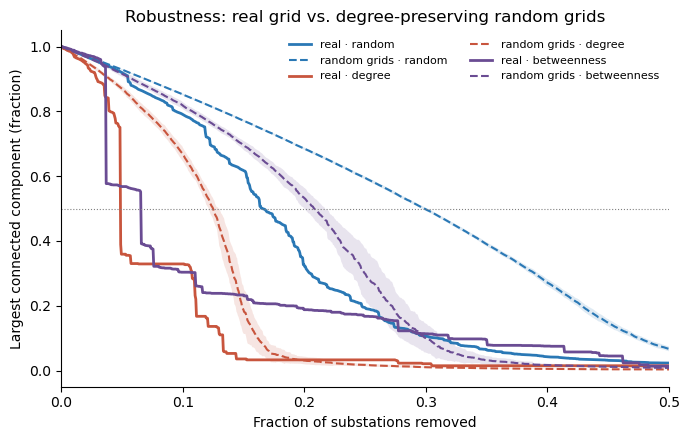

In [9]:
N = G.number_of_nodes()
frac = np.arange(N + 1) / N
cdf = pd.DataFrame({"fraction_removed": frac})
for k in null_curves:
    arr = np.array(null_curves[k])
    cdf[f"real_{k}"] = real_curves[k]
    cdf[f"null_{k}_mean"] = arr.mean(axis=0)
    cdf[f"null_{k}_std"] = arr.std(axis=0)
cdf.to_csv(RESULTS / "robustness_curves_null.csv", index=False)

colors = {"random": "#2a78b5", "degree": "#c8553d", "betweenness": "#6a4c93"}
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, c in colors.items():
    ax.plot(frac, cdf[f"real_{k}"], color=c, lw=2, label=f"real · {k}")
    m, s = cdf[f"null_{k}_mean"], cdf[f"null_{k}_std"]
    ax.plot(frac, m, color=c, lw=1.5, ls="--", label=f"random grids · {k}")
    ax.fill_between(frac, m - s, m + s, color=c, alpha=0.15, lw=0)
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
ax.set_xlim(0, 0.5)
ax.set_xlabel("Fraction of substations removed")
ax.set_ylabel("Largest connected component (fraction)")
ax.set_title("Robustness: real grid vs. degree-preserving random grids")
ax.legend(frameon=False, fontsize=8, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "robustness_real_vs_null.png", dpi=200)
plt.show()

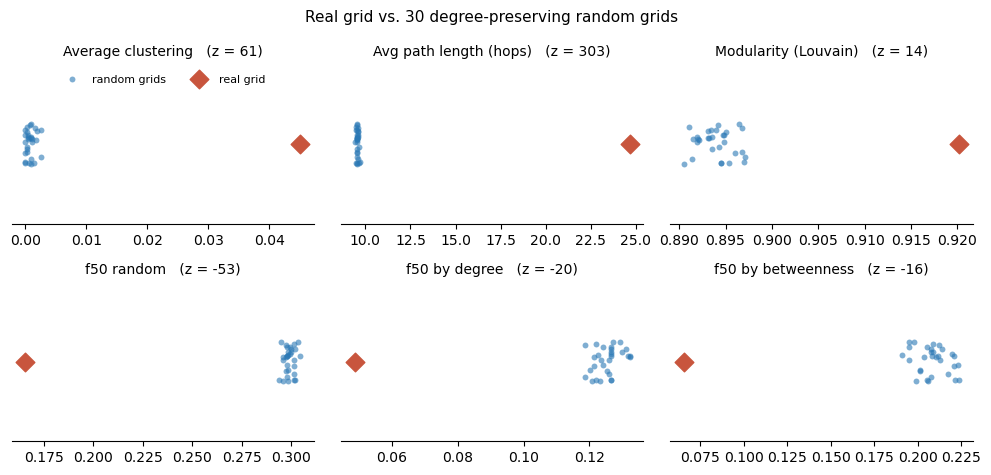

In [10]:
show = ["avg_clustering", "avg_path_length", "modularity",
        "f50_random", "f50_degree", "f50_betweenness"]
zi = zdf.set_index("metric")
jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(null))

fig, axes = plt.subplots(2, 3, figsize=(10, 4.8))
for ax, m in zip(axes.flat, show):
    ax.scatter(null[m], jitter, s=18, color="#2a78b5", alpha=0.6, lw=0, label="random grids")
    ax.scatter([real[m]], [0], s=90, marker="D", color="#c8553d", zorder=3, label="real grid")
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_title(f"{METRICS[m]}   (z = {zi.loc[m, 'z']:.0f})", fontsize=10)
    ax.spines[["top", "right", "left"]].set_visible(False)
axes.flat[0].legend(frameon=False, fontsize=8, loc="upper center", ncol=2)
fig.suptitle("Real grid vs. 30 degree-preserving random grids", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "null_zscores.png", dpi=200)
plt.show()

In [11]:
print("Real grid vs Ed's robustness numbers (16.6 %, 6.6 %, 4.9 %):")
print(f"  random {real.f50_random:.1%}, betweenness {real.f50_betweenness:.1%}, degree {real.f50_degree:.1%}")
print("Real grid vs Aneta's eda_stats.csv (avg clustering 0.045, path 24.65, diameter 64):")
print(f"  {real.avg_clustering:.3f}, {real.avg_path_length:.2f}, {real.diameter:.0f}")

print("\nResults log:")
print(f"Real vs {len(null)} random grids: clustering {real.avg_clustering:.3f} vs {null.avg_clustering.mean():.3f}, "
      f"path length {real.avg_path_length:.1f} vs {null.avg_path_length.mean():.1f} hops, "
      f"modularity {real.modularity:.2f} vs {null.modularity.mean():.2f}; "
      f"LCC < 50 % after {real.f50_random:.1%} vs {null.f50_random.mean():.1%} random removal "
      f"(degree {real.f50_degree:.1%} vs {null.f50_degree.mean():.1%}, "
      f"betweenness {real.f50_betweenness:.1%} vs {null.f50_betweenness.mean():.1%}). "
      f"All |z| > {np.floor(zdf.z.abs().min()):.0f}.")

Real grid vs Ed's robustness numbers (16.6 %, 6.6 %, 4.9 %):
  random 16.6%, betweenness 6.6%, degree 4.9%
Real grid vs Aneta's eda_stats.csv (avg clustering 0.045, path 24.65, diameter 64):
  0.045, 24.65, 64

Results log:
Real vs 30 random grids: clustering 0.045 vs 0.001, path length 24.7 vs 9.5 hops, modularity 0.92 vs 0.89; LCC < 50 % after 16.6% vs 29.9% random removal (degree 4.9% vs 12.5%, betweenness 6.6% vs 20.8%). All |z| > 9.
